# STN of GA trajectories on 2-opt basins
Location = 2-opt local optimum reached by best-improvement descent from the elite. First run generates GA trajectories (~1 min).

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import src.dl_permutations.contrastive_trajectory_learning as C

tsp = C.make_tsp()
data = C.drop_repeated_steps(C.load_or_generate_trajectories())
n = C.CITIES_COUNT
D = np.linalg.norm(tsp.cities[:, None] - tsp.cities[None], axis=-1)
I, J = np.array([(i, j) for i in range(n - 2) for j in range(i + 2, n) if (i, j) != (0, n - 1)]).T


def full(p):
    return np.r_[np.arange(C.START_CITY), p]


def two_opt(t):
    t, steps = t.copy(), 0
    while True:
        a, b, c, d = t[I], t[I + 1], t[J], t[(J + 1) % n]
        delta = D[a, c] + D[b, d] - D[a, b] - D[c, d]
        k = delta.argmin()
        if delta[k] > -1e-9:
            return t, steps
        t[I[k] + 1:J[k] + 1] = t[I[k] + 1:J[k] + 1][::-1]
        steps += 1


def edge_vec(t):
    v, w = np.zeros(n * n), np.roll(t, -1)
    v[np.minimum(t, w) * n + np.maximum(t, w)] = 1
    return v


optima, opt_id = [], {}


def basin(t):
    o, steps = two_opt(t)
    key = min(tuple(o[1:]), tuple(o[:0:-1]))
    if key not in opt_id:
        opt_id[key] = len(optima)
        optima.append(o)
    return opt_id[key], steps


np.random.seed(0)
ref = np.array([basin(full(p))[0] for p in tsp.generate_solutions(2000)])
lab, steps = map(np.array, zip(*(basin(full(p)) for p in data["perm"])))
opt_len = np.array([D[o, np.roll(o, -1)].sum() for o in optima])
ref_size = np.bincount(ref, minlength=len(optima)) / len(ref)
best = opt_len.argmin()

In [3]:
runs = np.unique(data["run_id"])
seqs = [s[np.r_[True, s[1:] != s[:-1]]] for s in (lab[data["run_id"] == r] for r in runs)]
edges = Counter((u, v) for s in seqs for u, v in zip(s[:-1], s[1:]))
visits = Counter(v for s in seqs for v in set(s))
ends = Counter(s[-1] for s in seqs)
nodes = np.array(sorted(visits))

print(f"reference: {len(np.unique(ref))} optima from {len(ref)} random starts | "
      f"best {opt_len[best]:.3f}, its basin = {ref_size[best]:.1%} of starts")
print(f"STN: {len(nodes)} nodes, {len(edges)} edges | {np.mean([len(s) for s in seqs]):.1f} basins/run | "
      f"optima never hit by random starts: {(ref_size[nodes] == 0).sum()}")
print(f"end nodes: {len(ends)} distinct | runs ending in best basin: {ends[best] / len(runs):.0%}")
for v, c in ends.most_common(5):
    print(f"  basin {v:3d}: {c:2d} runs | length {opt_len[v]:.3f} | random-start basin share {ref_size[v]:.1%}")

final = dict(zip(runs, (s[-1] for s in seqs)))
in_final = lab == np.array([final[r] for r in data["run_id"]])
gen_bin = np.digitize(data["generation"], [10, 30, 60])
for b, name in enumerate(["0-9", "10-29", "30-59", "60-99"]):
    m = gen_bin == b
    print(f"gen {name:>5}: {m.sum():4d} elites | 2-opt steps to optimum {steps[m].mean():4.1f} | "
          f"already in run's final basin {in_final[m].mean():.0%}")

reference: 54 optima from 2000 random starts | best 40.457, its basin = 18.2% of starts
STN: 48 nodes, 311 edges | 12.0 basins/run | optima never hit by random starts: 7
end nodes: 20 distinct | runs ending in best basin: 25%
  basin   1: 25 runs | length 40.457 | random-start basin share 18.2%
  basin  11: 18 runs | length 40.809 | random-start basin share 9.9%
  basin   3: 14 runs | length 41.049 | random-start basin share 10.2%
  basin   0: 13 runs | length 41.695 | random-start basin share 19.7%
  basin   6:  6 runs | length 42.288 | random-start basin share 12.0%
gen   0-9:  609 elites | 2-opt steps to optimum 11.1 | already in run's final basin 15%
gen 10-29:  550 elites | 2-opt steps to optimum  7.9 | already in run's final basin 21%
gen 30-59:  423 elites | 2-opt steps to optimum  6.0 | already in run's final basin 37%
gen 60-99:  272 elites | 2-opt steps to optimum  4.7 | already in run's final basin 69%


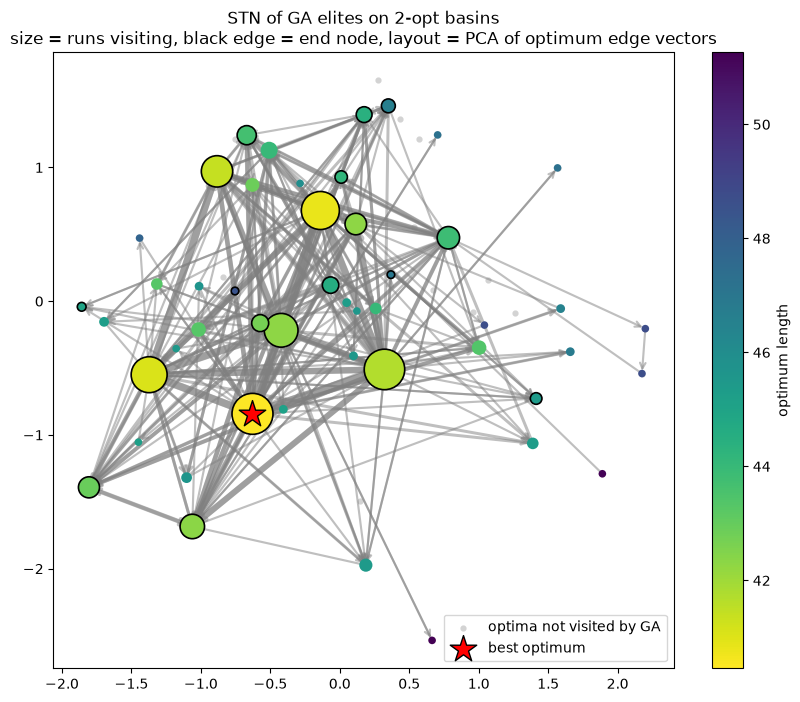

In [4]:
xy = PCA(2).fit_transform(np.array([edge_vec(o) for o in optima]))

fig, ax = plt.subplots(figsize=(10, 8))
for (u, v), c in edges.items():
    ax.annotate("", xy[v], xy[u], arrowprops=dict(arrowstyle="->", color="gray", alpha=0.5,
                                                  lw=0.5 + 1.5 * np.log1p(c)))
ax.scatter(*xy.T, s=12, c="lightgray", label="optima not visited by GA")
sc = ax.scatter(*xy[nodes].T, s=[20 + 10 * visits[v] for v in nodes], c=opt_len[nodes], cmap="viridis_r",
                edgecolors=["k" if v in ends else "none" for v in nodes], linewidths=1.2, zorder=3)
ax.scatter(*xy[best], marker="*", s=400, c="red", edgecolors="k", zorder=4, label="best optimum")
fig.colorbar(sc, label="optimum length")
ax.set_title("STN of GA elites on 2-opt basins\nsize = runs visiting, black edge = end node, layout = PCA of optimum edge vectors")
ax.legend()
fig.savefig(f"{C.OUTPUT_DIR}/stn_2opt_basins.png", dpi=150, bbox_inches="tight")
plt.show()